In [15]:
%pip install matplotlib scipy


     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 62.4/62.4 kB 910.0 kB/s eta 0:00:0036m0:00:01
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 35.3/35.3 MB 6.3 MB/s eta 0:00:00m eta 0:00:010:00:01m
Note: you may need to restart the kernel to use updated packages.


In [2]:
import matplotlib.pyplot as plt
import numpy as np

plt.style.use('_mpl-gallery')

# make data
x = np.linspace(0, 10, 100)
y = 0.5 + 0.04*x +0.0008*x**2
x2 = np.linspace(0, 10, 25)
y2 = 4 + 1 * np.sin(2 * x2)

# plot
fig, ax = plt.subplots()

ax.plot(x2, y2 + 2.5, 'x', markeredgewidth=2)
ax.plot(x, y, linewidth=2.0)
ax.plot(x2, y2 - 2.5, 'o-', linewidth=2)

ax.set(xlim=(0, 8), xticks=np.arange(1, 8)
       ylim=(0, 8), yticks=np.arange(1, 8))

plt.show()

SyntaxError: invalid syntax. Perhaps you forgot a comma? (2026525443.py, line 19)

In [3]:
import numpy as np


def calcular_histerese(subida, descida, fs_saida):
    """Calcula a histerese maxima absoluta e percentual."""
    diferencas = np.abs(np.array(subida) - np.array(descida))
    eh_max = np.max(diferencas)
    eh_perc = (eh_max / fs_saida) * 100
    return eh_max, eh_perc


def calcular_repetibilidade(leituras, fs_saida):
    """Calcula a repetibilidade com base no delta maximo."""
    delta_y_max = np.max(leituras) - np.min(leituras)
    rep_perc = (delta_y_max / fs_saida) * 100
    return delta_y_max, rep_perc


def calcular_reprodutibilidade(medias_operadores):
    """Calcula o Desvio Padrao Relativo (RSD) entre diferentes operadores."""
    media_global = np.mean(medias_operadores)
    desvio_padrao = np.std(medias_operadores, ddof=1)
    rsd_perc = (desvio_padrao / media_global) * 100

    if rsd_perc <= 0.5:
        classificacao = "Excelente"
    elif rsd_perc <= 2.0:
        classificacao = "Boa"
    elif rsd_perc <= 5.0:
        classificacao = "Aceitável"
    else:
        classificacao = "Ruim"

    return media_global, desvio_padrao, rsd_perc, classificacao


# --- DADOS DOS EXERCÍCIOS ---

# Exemplo Histerese (Questão 7)
v_subida = [0.10, 1.05, 2.02, 3.08, 4.05, 5.00]
v_descida = [0.10, 1.00, 1.92, 2.88, 3.91, 5.00]
fs_saida = 5.00 - 0.10  # y_max - y_min

eh_max, eh_perc = calcular_histerese(v_subida, v_descida, fs_saida)

# Exemplo Repetibilidade e Reprodutibilidade (Questão 9)
leituras_rep = [10.02, 10.03, 10.01, 10.02, 10.03]
fs_ref = 10.00

delta_y, rep_perc = calcular_repetibilidade(leituras_rep, fs_ref)

operador_a = np.mean([10.02, 10.03, 10.01])
operador_b = np.mean([10.30, 10.28, 10.31])
operador_c = np.mean([9.80, 9.82, 9.81])

media_g, std_g, rsd, classe = calcular_reprodutibilidade(
    [operador_a, operador_b, operador_c]
)

# --- EXIBIÇÃO DOS RESULTADOS ---

print("=== HISTERESE ===")
print(f"Histerese Máxima (eh): {eh_max:.2f} V")
print(f"Histerese (%): {eh_perc:.2f}%\n")

print("=== REPETIBILIDADE ===")
print(f"Delta Y Máximo: {delta_y:.2f}")
print(f"Repetibilidade (%): {rep_perc:.2f}%\n")

print("=== REPRODUTIBILIDADE ===")
print(f"Média Global: {media_g:.4f}")
print(f"Desvio Padrão (σ): {std_g:.4f}")
print(f"RSD (%): {rsd:.2f}%")
print(f"Classificação: {classe}")

=== HISTERESE ===
Histerese Máxima (eh): 0.20 V
Histerese (%): 4.08%

=== REPETIBILIDADE ===
Delta Y Máximo: 0.02
Repetibilidade (%): 0.20%

=== REPRODUTIBILIDADE ===
Média Global: 10.0422
Desvio Padrão (σ): 0.2441
RSD (%): 2.43%
Classificação: Aceitável


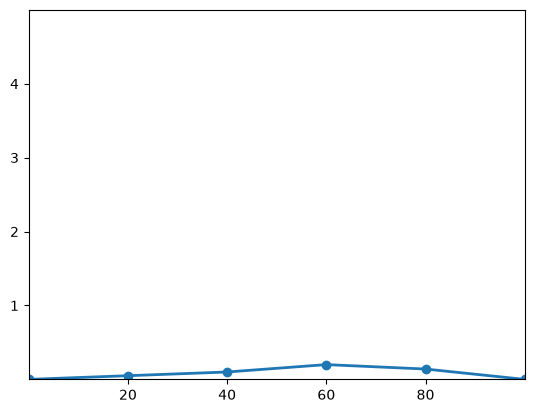

In [3]:
import numpy as np
import matplotlib.pyplot as plt

# Força aplicada F em Newtons (N)
F = np.array([0, 20, 40, 60, 80, 100])

# Tensão de saída Vmedido na subida (V)
V_subida = np.array([0.10, 1.05, 2.02, 3.08, 4.05, 5.00])

# Tensão de saída Vmedido na descida (V)
V_descida = np.array([0.10, 1.00, 1.92, 2.88, 3.91, 5.00])
y = V_subida - V_descida

# plot
fig, ax = plt.subplots()

# ax.plot(F, V_descida, 'x', markeredgewidth=2)
# ax.plot(F, V_subida, linewidth=2.0)
ax.plot(F, y, 'o-', linewidth=2)

ax.set(xlim=(0, 100), xticks=np.arange(20, 100, 20),
       ylim=(0, 5), yticks=np.arange(1, 5, 1))

plt.show()

In [ ]:


F = np.array([0, 20, 40, 60, 80, 100])
V_subida = np.array([0.10, 1.05, 2.02, 3.08, 4.05, 5.00])
V_descida = np.array([0.10, 1.00, 1.92, 2.88, 3.91, 5.00])

# Media das curvas para amortecer a histerese
V_medio = (V_subida + V_descida) / 2

# Ajuste linear de 1 grau: V(F) = K*F + V0
K, V0 = np.polyfit(F, V_medio, 1)

print(f"V(F) = {K:.5f} * F + {V0:.5f}")
# Resultado aprox: V(F) = 0.04907 * F + 0.03810
G = 

V(F) = 0.04911 * F + 0.05381


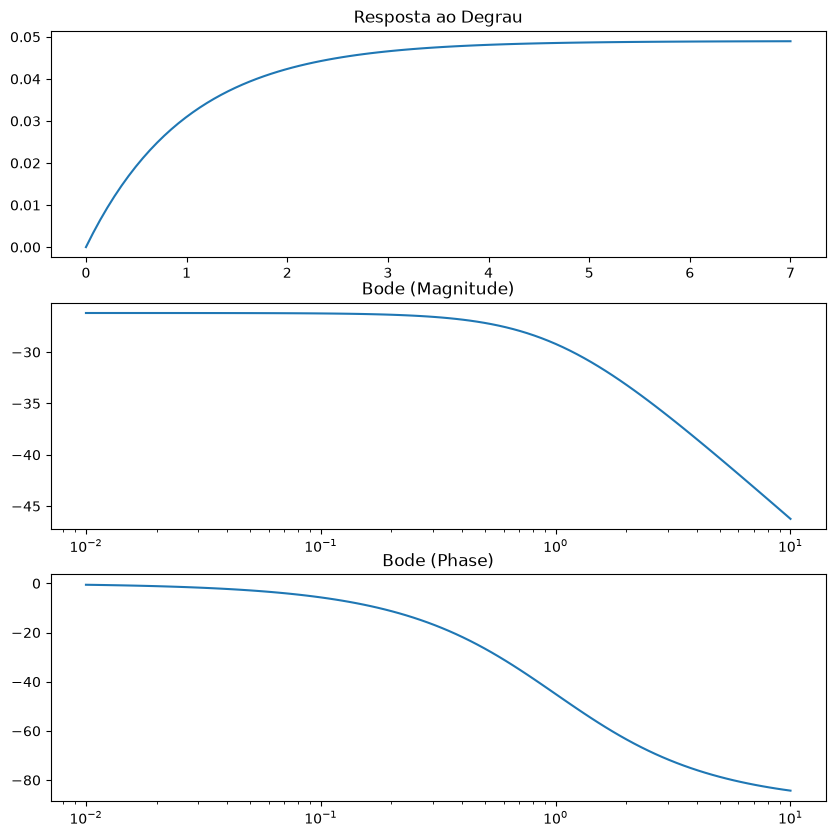

In [20]:

import matplotlib.pyplot as plt
from scipy import signal

# G(s) = 0.049 / (s + 1)
sys = signal.TransferFunction([0.049], [1.0, 1])

t, y = signal.step(sys)
w, mag, phase = signal.bode(sys)

plt.figure(figsize=(10, 10))
plt.subplot(3, 1, 1)
plt.plot(t, y)
plt.title('Resposta ao Degrau')

plt.subplot(3, 1, 2)
plt.semilogx(w, mag)
plt.title('Bode (Magnitude)')

plt.subplot(3, 1, 3)
plt.semilogx(w, phase)
plt.title('Bode (Phase)')


plt.show()

In [5]:
# Let's verify the calculations from the image and check exact values

positions = [0, 0.2, 0.4, 0.6, 1] # mm
r_medida = [0, 8280, 16380, 21510, 23850] # kOhms
v_medido = [0.0, 1.39, 3.39, 4.45, 4.60] # V

# Vout calculado a partir da resistência medida (com base no divisor de tensão para um pot de 20k nom)
# Vout = 5 * (R_medida / 20k)
v_calc_from_r = [5 * (r / 20000) for r in r_medida]

# Vout teórico linear considerando o curso (assumindo 5cm = 20k, ou seja 4k por cm):
# Se 5cm é o curso total:
r_teorico = [p * (20.0 /20.0) for p in positions] # kOhms
v_teorico = [5 * r for r in r_teorico] # V

print("R medido (kOhm):", r_medida)
print("Vout medido (V):", v_medido)
print("R teórico (kOhm):", r_teorico) 
print("Vout teórico (V):", v_teorico)  
print("Vout calculado (a partir do R medido, 20k total):", v_calc_from_r)

R medido (kOhm): [0, 8280, 16380, 21510, 23850]
Vout medido (V): [0.0, 1.39, 3.39, 4.45, 4.6]
R teórico (kOhm): [0.0, 0.2, 0.4, 0.6, 1.0]
Vout teórico (V): [0.0, 1.0, 2.0, 3.0, 5.0]
Vout calculado (a partir do R medido, 20k total): [0.0, 2.07, 4.095, 5.3774999999999995, 5.9624999999999995]


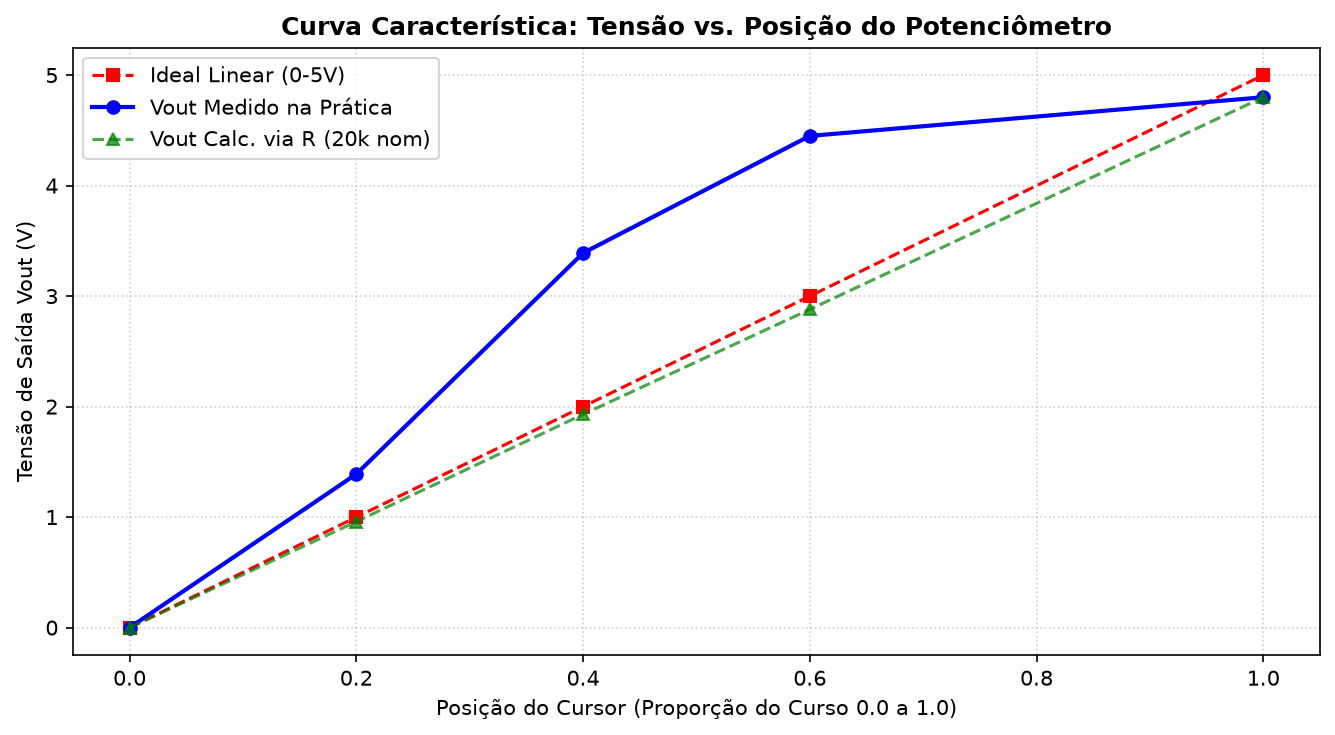

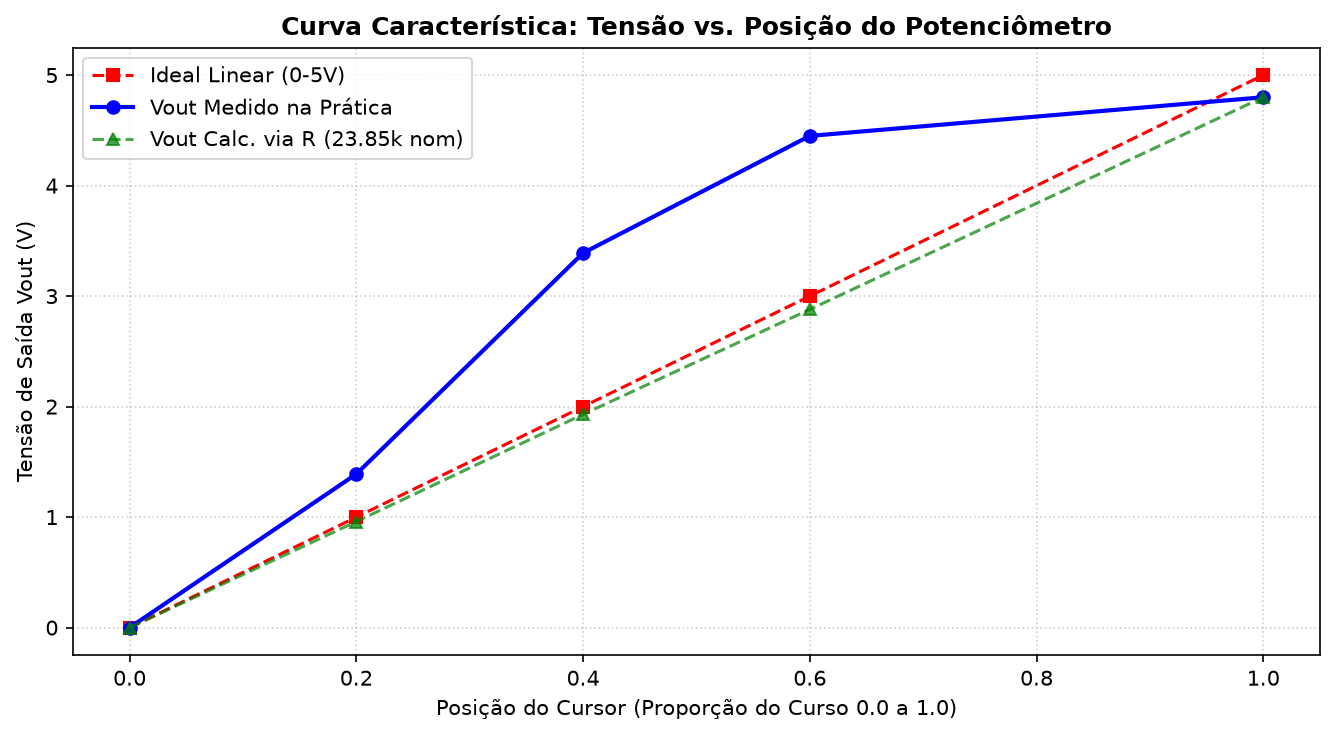

In [4]:
import matplotlib.pyplot as plt

# Dados do experimento
positions = [0, 0.2, 0.4, 0.6, 1.0]  # Posição relativa do curso (0 a 1)
r_medida = [0, 8280, 16380, 21510, 23850]  # Resistência medida (Ohms)
v_medido = [0.0, 1.39, 3.39, 4.45, 4.80]  # Tensão medida (Volts)

# Reta ideal linear (0 V a 5 V)
v_teorico = [5.0 * p for p in positions]

# Vout calculado via divisor de tensão usando R nominal de 20 kΩ
v_calc_from_r = [0, 0.96, 1.93, 2.88, 4.80] 

# Configuração do gráfico
plt.figure(figsize=(9, 5), dpi=150)

plt.plot(positions, v_teorico, 'r--', label='Ideal Linear (0-5V)', marker='s')
plt.plot(positions, v_medido, 'b-o', label='Vout Medido na Prática', linewidth=2)
plt.plot(positions, v_calc_from_r, 'g--^', label='Vout Calc. via R (20k nom)', alpha=0.7)

# Formatação visual
plt.title('Curva Característica: Tensão vs. Posição do Potenciômetro', fontsize=12, fontweight='bold')
plt.xlabel('Posição do Cursor (Proporção do Curso 0.0 a 1.0)', fontsize=10)
plt.ylabel('Tensão de Saída Vout (V)', fontsize=10)
plt.grid(True, linestyle=':', alpha=0.6)
plt.legend(loc='upper left')

plt.tight_layout()
plt.show()

# Dados do experimento
positions = [0, 0.2, 0.4, 0.6, 1.0]  # Posição relativa do curso (0 a 1)
r_medida = [0, 8280, 16380, 21510, 23850]  # Resistência medida (Ohms)
v_medido = [0.0, 1.39, 3.39, 4.45, 4.8]  # Tensão medida (Volts)

# Reta ideal linear (0 V a 5 V)
v_teorico = [5.0 * p for p in positions]

# Vout calculado via divisor de tensão usando R nominal de 20 kΩ
v_calc_from_r = [0, 0.96, 1.93, 2.88, 4.80]

# Configuração do gráfico
plt.figure(figsize=(9, 5), dpi=150)

plt.plot(positions, v_teorico, 'r--', label='Ideal Linear (0-5V)', marker='s')
plt.plot(positions, v_medido, 'b-o', label='Vout Medido na Prática', linewidth=2)
plt.plot(positions, v_calc_from_r, 'g--^', label='Vout Calc. via R (23.85k nom)', alpha=0.7)

# Formatação visual
plt.title('Curva Característica: Tensão vs. Posição do Potenciômetro', fontsize=12, fontweight='bold')
plt.xlabel('Posição do Cursor (Proporção do Curso 0.0 a 1.0)', fontsize=10)
plt.ylabel('Tensão de Saída Vout (V)', fontsize=10)
plt.grid(True, linestyle=':', alpha=0.6)
plt.legend(loc='upper left')

plt.tight_layout()
plt.show()